<center>
<img src="img/logo-hds.png" width="650"/>

***

<center>Lecture 7</center>

***

<center>Automated Time-Series Feature Extraction with tsfresh</center>  

***

<center>26 October 2026<center>
<center>Rahman Peimankar<center>

## Where we are in the course

Lecture 4:

**raw signal → quality → filtering → segmentation**

Lecture 5:

**cleaned signal → physiological events → interpretable features**

Lecture 6:

**project progress + peer feedback**

Today:

**segmented time series → automated features → feature selection → project table**


## Learning outcomes

By the end of today you should be able to:

1. explain why automated feature extraction can be useful;
2. reshape biosignal windows into the long format required by `tsfresh`;
3. extract a small or efficient set of time-series features;
4. impute invalid feature values;
5. use supervised feature selection carefully;
6. inspect selected features visually;
7. connect automated features to project workflows;
8. avoid leakage when using windows from the same subject or record.

## Curated vs automated features

### Curated physiological features
From Lecture 5:

- R-peaks;
- RR intervals;
- mean heart rate;
- SDNN;
- RMSSD.

They are interpretable and connected to physiology.

### Automated time-series features
Today:

- mean, variance, quantiles;
- autocorrelation;
- peaks;
- energy-like measures;
- frequency-related descriptors;
- many others.

They are useful when we want broad signal descriptions, but they are easier to misuse.

## What is tsfresh?

`tsfresh` stands for:

**Time Series FeatuRe Extraction based on Scalable Hypothesis tests**

It can:

- calculate many time-series features automatically;
- work with pandas DataFrames;
- support different sensors/channels;
- select statistically relevant features for a target variable.

Today we use it for **biosignal windows**, not for real-time streaming.

## Our running example

We will create a small signal-quality classification toy example.

### Data

- clean ECG: MIT-BIH record `119`;
- noisy ECG: NSTDB record `119e12`;
- interval starts at 305 s, after noise has begun;
- channel 0;
- 10-second windows.

### Target

`0 = clean`  
`1 = noisy`

The goal is not to build a clinical classifier.

The goal is to learn the **tsfresh workflow**.

## Setup

We combine:

- `wfdb` for real PhysioNet signals;
- `tsfresh` for automated feature extraction;
- `pandas` for the long-format table and feature matrix;
- `matplotlib` for inspection.

In [1]:
# Run once if needed:
%pip install wfdb tsfresh scipy pandas matplotlib numpy scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from tsfresh import extract_features, select_features
from tsfresh.feature_extraction import MinimalFCParameters, EfficientFCParameters
from tsfresh.utilities.dataframe_functions import impute

plt.rcParams["figure.figsize"] = (12, 4)

## Load clean and noisy ECG segments

We load two aligned 120-second intervals:

- `119` from MIT-BIH;
- `119e12` from NSTDB.

Both are real PhysioNet WFDB records.

In [3]:
clean_name = "119"
noisy_name = "119e12"

start_s = 305
duration_s = 120

header = wfdb.rdheader(noisy_name, pn_dir="nstdb")
fs = header.fs

sampfrom = int(start_s * fs)
sampto = int((start_s + duration_s) * fs)

clean_record = wfdb.rdrecord(
    clean_name,
    pn_dir="mitdb",
    sampfrom=sampfrom,
    sampto=sampto
)

noisy_record = wfdb.rdrecord(
    noisy_name,
    pn_dir="nstdb",
    sampfrom=sampfrom,
    sampto=sampto
)

x_clean = clean_record.p_signal[:, 0]
x_noisy = noisy_record.p_signal[:, 0]
t = np.arange(len(x_clean)) / fs

print("Sampling frequency:", fs)
print("Clean channels:", clean_record.sig_name)
print("Noisy channels:", noisy_record.sig_name)

Sampling frequency: 360
Clean channels: ['MLII', 'V1']
Noisy channels: ['MLII', 'V1']


## Inspect before extracting features

Automated feature extraction should not skip biosignal inspection.

Look for:

- baseline drift;
- abrupt artefacts;
- high-frequency noise;
- preserved or obscured QRS complexes.

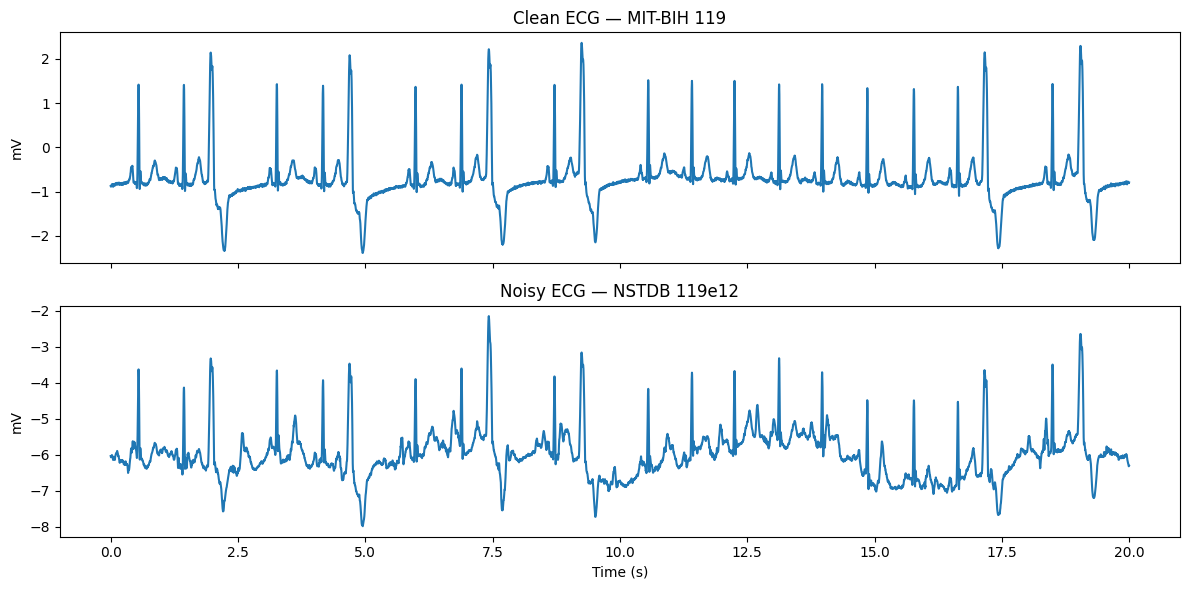

In [4]:
show_s = 20
n_show = int(show_s * fs)

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax[0].plot(t[:n_show], x_clean[:n_show])
ax[0].set_title("Clean ECG — MIT-BIH 119")
ax[0].set_ylabel(clean_record.units[0])

ax[1].plot(t[:n_show], x_noisy[:n_show])
ax[1].set_title("Noisy ECG — NSTDB 119e12")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel(noisy_record.units[0])

plt.tight_layout()
plt.show()

## Create fixed windows

We split both signals into 10-second non-overlapping windows.

Each window will become one row in the feature matrix.

For the target:

- clean windows → `label = 0`
- noisy windows → `label = 1`

In [5]:
def make_window_rows(x, fs, label, source, window_s=10):
    window_samples = int(window_s * fs)
    rows = []

    for start in range(0, len(x) - window_samples + 1, window_samples):
        window_id = f"{source}_{start // window_samples:03d}"
        w = x[start:start + window_samples]

        rows.append({
            "id": window_id,
            "source": source,
            "label": label,
            "start_s": start / fs,
            "signal": w
        })

    return rows

window_rows = (
    make_window_rows(x_clean, fs, label=0, source="clean", window_s=10)
    + make_window_rows(x_noisy, fs, label=1, source="noisy", window_s=10)
)

windows_df = pd.DataFrame(window_rows)

windows_df[["id", "source", "label", "start_s"]].head()

,id,source,label,start_s
0,clean_000,clean,0,0.0
1,clean_001,clean,0,10.0
2,clean_002,clean,0,20.0
3,clean_003,clean,0,30.0
4,clean_004,clean,0,40.0


## What format does tsfresh expect?

`tsfresh` works well with a **long-format** DataFrame.

For one univariate signal, each row is one sample:

| id | time | kind | value |
|---|---:|---|---:|
| clean_000 | 0 | ECG | 0.12 |
| clean_000 | 1 | ECG | 0.13 |
| ... | ... | ECG | ... |

Important columns:

- `id`: which time series/window?
- `time`: sample order or time;
- `kind`: sensor/channel name;
- `value`: signal value.

## Build the long-format table

This step is often the most confusing part of tsfresh.

We convert our list of windows into one sample-level table.

In [7]:
def windows_to_tsfresh_long(windows_df, signal_name="ECG"):
    long_parts = []

    for _, row in windows_df.iterrows():
        x = row["signal"]

        tmp = pd.DataFrame({
            "id": row["id"],
            "time": np.arange(len(x)),
            "kind": signal_name,
            "value": x
        })

        long_parts.append(tmp)

    return pd.concat(long_parts, ignore_index=True)

long_df = windows_to_tsfresh_long(windows_df, signal_name="ECG")

print(long_df.shape)
long_df.head()

(86400, 4)


,id,time,kind,value
0,clean_000,0,ECG,-0.870
1,clean_000,1,ECG,-0.885
2,clean_000,2,ECG,-0.885
3,clean_000,3,ECG,-0.885
4,clean_000,4,ECG,-0.870


### Add the target vector

For supervised feature selection, the target index must match the feature-matrix index.

Here:

- `id` identifies the window;
- `label` says clean or noisy.


In [8]:
y = windows_df.set_index("id")["label"]

print(y.head())
print(y.value_counts())

id
clean_000    0
clean_001    0
clean_002    0
clean_003    0
clean_004    0
Name: label, dtype: int64
label
0    12
1    12
Name: count, dtype: int64


## First extraction: minimal features

`MinimalFCParameters()` computes only a small feature set.

This is excellent for teaching and debugging because:

- it is fast;
- the output is easier to inspect;
- the feature names are understandable.

Start small before using large feature sets.

In [9]:
minimal_settings = MinimalFCParameters()

X_minimal = extract_features(
    long_df,
    column_id="id",
    column_sort="time",
    column_kind="kind",
    column_value="value",
    default_fc_parameters=minimal_settings,
    disable_progressbar=False
)

print(X_minimal.shape)
X_minimal.head()

Feature Extraction: 100%|██████████| 24/24 [00:13<00:00,  1.73it/s]

(24, 10)


,ECG__sum_values,ECG__median,ECG__mean,ECG__length,ECG__standard_deviation,ECG__variance,ECG__root_mean_square,ECG__maximum,ECG__absolute_maximum,ECG__minimum
clean_000,-2635.445,-0.810,-0.732068,3600.0,0.622164,0.387089,0.960735,2.365,2.385,-2.385
clean_001,-2425.580,-0.755,-0.673772,3600.0,0.502714,0.252721,0.840649,2.295,2.295,-2.280
clean_002,-2367.120,-0.740,-0.657533,3600.0,0.590454,0.348636,0.883734,2.300,2.345,-2.345
clean_003,-2160.480,-0.690,-0.600133,3600.0,0.587546,0.345210,0.839863,2.315,2.315,-2.275
clean_004,-2621.180,-0.820,-0.728106,3600.0,0.504150,0.254167,0.885610,2.225,2.370,-2.370


### Inspect the generated feature names

tsfresh uses names such as:

```text
ECG__mean
ECG__standard_deviation
ECG__minimum
```

The prefix identifies the signal `kind`.


In [10]:
print(X_minimal.columns.tolist())

['ECG__sum_values', 'ECG__median', 'ECG__mean', 'ECG__length', 'ECG__standard_deviation', 'ECG__variance', 'ECG__root_mean_square', 'ECG__maximum', 'ECG__absolute_maximum', 'ECG__minimum']


## Impute invalid values

Some feature calculators can return:

- NaN;
- infinite values;
- undefined values for short or constant signals.

Use:

```python
impute(X)
```

before feature selection or modelling.

In [11]:
X_minimal_imputed = X_minimal.copy()
impute(X_minimal_imputed)

X_minimal_imputed.isna().sum().sum()

np.int64(0)

## Visualize a simple extracted feature

For the clean/noisy example, standard deviation and range may differ.

But remember:

- feature values summarize a window;
- they do not show where in the window the problem occurred;
- visual inspection remains important.

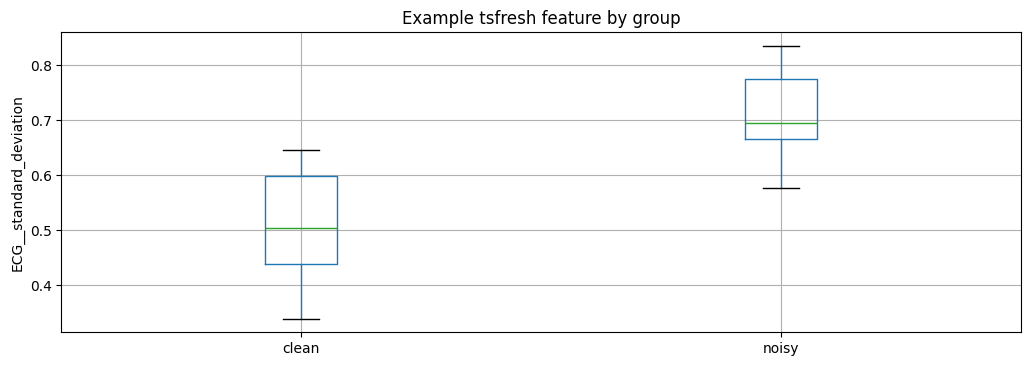

In [12]:
feature_name = "ECG__standard_deviation"

plot_df = X_minimal_imputed[[feature_name]].join(y.rename("label"))
plot_df["group"] = plot_df["label"].map({0: "clean", 1: "noisy"})

plot_df.boxplot(column=feature_name, by="group")
plt.suptitle("")
plt.title("Example tsfresh feature by group")
plt.xlabel("")
plt.ylabel(feature_name)
plt.show()

## More features: EfficientFCParameters

`EfficientFCParameters()` calculates many features while avoiding those with high computational cost.

This is a practical option for teaching and small projects.

For large datasets:

- start with a few records;
- test runtime;
- document settings;
- avoid extracting features blindly from every raw sample.

In [13]:
efficient_settings = EfficientFCParameters()

X = extract_features(
    long_df,
    column_id="id",
    column_sort="time",
    column_kind="kind",
    column_value="value",
    default_fc_parameters=efficient_settings,
    disable_progressbar=False,
    n_jobs=0
)

print(X.shape)
X.head()

Feature Extraction: 100%|██████████| 24/24 [00:19<00:00,  1.25it/s]

(24, 777)


,ECG__variance_larger_than_standard_deviation,ECG__has_duplicate_max,ECG__has_duplicate_min,ECG__has_duplicate,ECG__sum_values,ECG__abs_energy,ECG__mean_abs_change,ECG__mean_change,ECG__mean_second_derivative_central,ECG__median,...,ECG__fourier_entropy__bins_5,ECG__fourier_entropy__bins_10,ECG__fourier_entropy__bins_100,ECG__permutation_entropy__dimension_3__tau_1,ECG__permutation_entropy__dimension_4__tau_1,ECG__permutation_entropy__dimension_5__tau_1,ECG__permutation_entropy__dimension_6__tau_1,ECG__permutation_entropy__dimension_7__tau_1,ECG__query_similarity_count__query_None__threshold_0.0,ECG__mean_n_absolute_max__number_of_maxima_7
clean_000,0.0,0.0,1.0,1.0,-2635.445,3322.844075,0.029454,0.000026,0.000002,-0.810,...,0.239211,0.305728,0.735537,1.570057,2.436388,3.419490,4.482358,5.396653,NaN,2.370714
clean_001,0.0,1.0,0.0,1.0,-2425.580,2544.085800,0.028268,-0.000007,0.000004,-0.755,...,0.249958,0.350689,0.930168,1.562047,2.419230,3.417830,4.474407,5.362565,NaN,2.281429
clean_002,0.0,0.0,0.0,1.0,-2367.120,2811.548900,0.029771,0.000032,0.000002,-0.740,...,0.204871,0.305728,0.812468,1.571465,2.419443,3.388184,4.435641,5.337074,NaN,2.331429
clean_003,0.0,0.0,0.0,1.0,-2160.480,2539.332700,0.030893,-0.000099,-0.000015,-0.690,...,0.235155,0.305728,0.761623,1.556887,2.393549,3.345029,4.393179,5.263533,NaN,2.305714
clean_004,0.0,0.0,0.0,1.0,-2621.180,2823.496950,0.028996,0.000154,-0.000022,-0.820,...,0.215617,0.294982,0.893872,1.554285,2.381982,3.322623,4.350529,5.228374,NaN,2.357857


### Prepare the larger feature matrix

Before feature selection:

1. impute invalid values;
2. align `X` and `y` by index;
3. check shapes and class counts.


In [14]:
X_imputed = X.copy()
impute(X_imputed)

y_aligned = y.loc[X_imputed.index]

print("X shape:", X_imputed.shape)
print("y shape:", y_aligned.shape)
print(y_aligned.value_counts())

X shape: (24, 777)
y shape: (24,)
label
0    12
1    12
Name: count, dtype: int64


C:\Users\abpe\AppData\Local\anaconda3\envs\rise\Lib\site-packages\tsfresh\utilities\dataframe_functions.py:198: RuntimeWarning: The columns ['ECG__query_similarity_count__query_None__threshold_0.0'] did not have any finite values. Filling with zeros.
  warnings.warn(


## Supervised feature selection

`select_features(X, y)` keeps features statistically associated with the target.

In this toy example, the target is **clean vs noisy**.

Important:

- feature selection uses labels;
- therefore, it must be inside the training workflow later;
- doing selection before train/test splitting can cause leakage.

In [15]:
X_selected = select_features(
    X_imputed,
    y_aligned
)

print("Original feature count:", X_imputed.shape[1])
print("Selected feature count:", X_selected.shape[1])

X_selected.head()

Original feature count: 777
Selected feature count: 201


,ECG__number_crossing_m__m_0,ECG__number_crossing_m__m_1,ECG__value_count__value_-1,ECG__count_below__t_0,ECG__range_count__max_1000000000000.0__min_0,ECG__range_count__max_0__min_-1000000000000.0,ECG__number_crossing_m__m_-1,ECG__range_count__max_1__min_-1,ECG__count_above__t_0,ECG__number_peaks__n_1,...,"ECG__cwt_coefficients__coeff_14__w_5__widths_(2, 5, 10, 20)",ECG__lempel_ziv_complexity__bins_3,ECG__autocorrelation__lag_4,"ECG__change_quantiles__f_agg_""var""__isabs_False__qh_1.0__ql_0.4",ECG__autocorrelation__lag_5,ECG__ratio_beyond_r_sigma__r_2.5,"ECG__change_quantiles__f_agg_""mean""__isabs_False__qh_0.6__ql_0.2",ECG__cid_ce__normalize_True,ECG__autocorrelation__lag_3,ECG__autocorrelation__lag_2
clean_000,22.0,22.0,11.0,0.942222,209.0,3391.0,26.0,2903.0,0.058056,438.0,...,-0.086362,0.063333,0.913779,0.007709,0.875171,0.049722,0.000290,6.794869,0.948374,0.975993
clean_001,22.0,22.0,4.0,0.954722,163.0,3437.0,16.0,3251.0,0.045278,444.0,...,-0.034036,0.060278,0.866252,0.007904,0.809288,0.048889,-0.000118,8.545036,0.918887,0.961880
clean_002,22.0,22.0,3.0,0.946667,192.0,3408.0,12.0,3112.0,0.053333,449.0,...,-0.077483,0.058056,0.898812,0.008151,0.854450,0.055000,0.000166,7.391164,0.939083,0.971551
clean_003,24.0,24.0,4.0,0.942500,207.0,3393.0,9.0,3179.0,0.057500,435.0,...,0.064993,0.059722,0.891371,0.008592,0.844132,0.055556,0.000228,7.659794,0.934427,0.969276
clean_004,22.0,22.0,11.0,0.956389,157.0,3443.0,36.0,3216.0,0.043611,435.0,...,-0.215919,0.066389,0.863073,0.008240,0.804335,0.051389,-0.000064,8.619155,0.917066,0.961024


## Inspect and visualize selected features

Feature selection is not the final answer.

We still ask:

- does the feature make sense?
- is it driven by artefact or physiology?
- would it generalize to another record, sensor, or patient?
- is the feature stable across windows?

Then we inspect selected feature names and visualize one example.

A strong separation in this tiny example does **not** prove generalization.


In [16]:
selected_names = X_selected.columns.tolist()

print("First selected features:")
for name in selected_names[:10]:
    print("-", name)

First selected features:
- ECG__number_crossing_m__m_0
- ECG__number_crossing_m__m_1
- ECG__value_count__value_-1
- ECG__count_below__t_0
- ECG__range_count__max_1000000000000.0__min_0
- ECG__range_count__max_0__min_-1000000000000.0
- ECG__number_crossing_m__m_-1
- ECG__range_count__max_1__min_-1
- ECG__count_above__t_0
- ECG__number_peaks__n_1


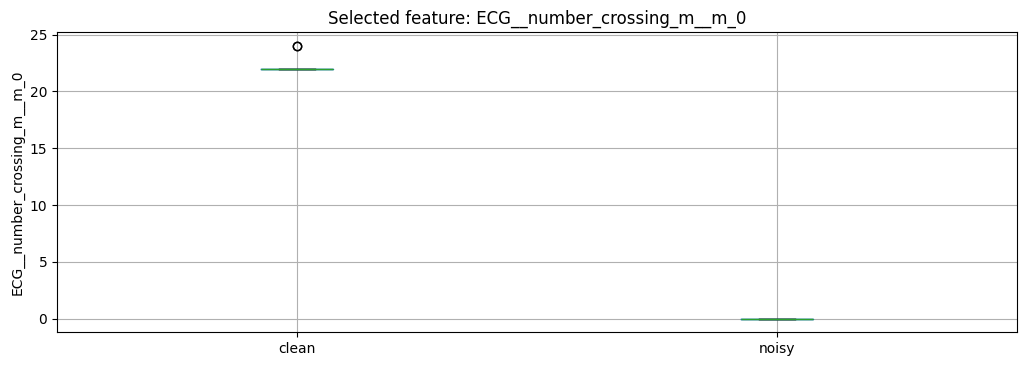

In [17]:
if len(selected_names) > 0:
    feature_name = selected_names[0]

    plot_df = X_selected[[feature_name]].join(y_aligned.rename("label"))
    plot_df["group"] = plot_df["label"].map({0: "clean", 1: "noisy"})

    plot_df.boxplot(column=feature_name, by="group")
    plt.suptitle("")
    plt.title(f"Selected feature: {feature_name}")
    plt.xlabel("")
    plt.ylabel(feature_name)
    plt.show()
else:
    print("No features selected. Try more data or a different target.")

## What selected features mean — and do not mean

A selected tsfresh feature means:

> this feature showed a statistical relationship with the target in this dataset.

It does **not** automatically mean:

- the feature is causal;
- the feature is clinically meaningful;
- it will work on another dataset;
- it is robust to different sensors;
- it is safe to use after leakage.

Feature extraction gives candidates.  
Science and validation decide usefulness.

## Multichannel format

For multiple signals, keep the same `id` and `time`, but change `kind`.

Example:

| id | time | kind | value |
|---|---:|---|---:|
| patient01_window00 | 0 | ECG | ... |
| patient01_window00 | 0 | PLETH | ... |
| patient01_window00 | 1 | ECG | ... |
| patient01_window00 | 1 | PLETH | ... |

tsfresh will produce columns such as:

- `ECG__mean`
- `PLETH__mean`
- `ECG__standard_deviation`
- `PLETH__standard_deviation`

## Feature tables need metadata

A tsfresh feature matrix usually does not contain all information needed for analysis.

Keep metadata such as:

- record ID;
- participant ID;
- window start/end time;
- signal/channel;
- label or outcome;
- sampling frequency;
- preprocessing settings;
- data split group.

Without metadata, features are hard to interpret and easy to misuse.

In [20]:
metadata = windows_df.set_index("id")[
    ["source", "label", "start_s"]
]

feature_table = metadata.join(X_minimal_imputed)

feature_table.head()

,source,label,start_s,ECG__sum_values,ECG__median,ECG__mean,ECG__length,ECG__standard_deviation,ECG__variance,ECG__root_mean_square,ECG__maximum,ECG__absolute_maximum,ECG__minimum
id,,,,,,,,,,,,,
clean_000,clean,0,0.0,-2635.445,-0.810,-0.732068,3600.0,0.622164,0.387089,0.960735,2.365,2.385,-2.385
clean_001,clean,0,10.0,-2425.580,-0.755,-0.673772,3600.0,0.502714,0.252721,0.840649,2.295,2.295,-2.280
clean_002,clean,0,20.0,-2367.120,-0.740,-0.657533,3600.0,0.590454,0.348636,0.883734,2.300,2.345,-2.345
clean_003,clean,0,30.0,-2160.480,-0.690,-0.600133,3600.0,0.587546,0.345210,0.839863,2.315,2.315,-2.275
clean_004,clean,0,40.0,-2621.180,-0.820,-0.728106,3600.0,0.504150,0.254167,0.885610,2.225,2.370,-2.370


## Leakage warning: windows are not independent patients

If one recording creates many windows, those windows are related.

Bad idea later:

```text
same patient's windows in both train and test
```

This can make performance look much better than it really is.

Better:

- split by participant or recording;
- then extract/select features inside the training workflow;
- keep test data untouched until final evaluation.

## Practical workflow for your project

A reproducible project should include:

1. dataset documentation in `data/README.md`;
2. loading code using WFDB or documented local files;
3. preprocessing choices;
4. window creation;
5. long-format table creation;
6. tsfresh settings object;
7. feature extraction;
8. imputation;
9. feature selection strategy;
10. feature table saved to `features/`.

The raw data should not be pushed to GitHub.

Physiological features from NeuroKit2 and automated tsfresh features can be combined in the same project table when scientifically justified.


## Exercise 1 — Extract tsfresh features (30 min)

Use **MIT-BIH record `103`**, channel 0.

### Tasks

1. load the first 120 s;
2. create 10 s non-overlapping windows;
3. convert windows into tsfresh long format;
4. extract `MinimalFCParameters`;
5. impute the feature matrix;
6. create a metadata + feature table;
7. plot one extracted feature across window start time.

### Starter code
Complete the `TODO`s below.

In [21]:
exercise_record = "103"
exercise_duration_s = 120
window_s = 10

# TODO 1: load record 103 from MIT-BIH
# hdr_ex = ...
# fs_ex = ...
# rec_ex = ...
# x_ex = ...

# TODO 2: create windows with ids and start times
exercise_windows = []

In [22]:
# TODO 3: convert exercise_windows into long format
# Required columns: id, time, kind, value

# ex_long = ...

# TODO 4: extract minimal tsfresh features
# X_ex = extract_features(...)

# TODO 5: impute
# impute(X_ex)

# TODO 6: join metadata and features into one table
# ex_feature_table = ...
# ex_feature_table.head()

In [23]:
# TODO 7: plot one feature across start time

# feature_name = ...
# plt.plot(...)
# plt.xlabel("Window start time (s)")
# plt.ylabel(feature_name)
# plt.title(...)
# plt.show()

## Exercise 2 — Feature selection (30 min)

### Clean vs noisy windows

Use:

- clean MIT-BIH `118`;
- noisy NSTDB `118e12`;
- start time 305 s;
- duration 120 s;
- 10 s windows.

Tasks:

1. create clean/noisy windows;
2. build long-format table;
3. extract `EfficientFCParameters`;
4. impute features;
5. run `select_features`;
6. inspect the first 5 selected features.


In [1]:
# Starter code

# TODO 1: load clean record 118 and noisy record 118e12
# TODO 2: create window metadata with id, label, source, start_s
# TODO 3: create long-format DataFrame

# long_118 = ...
# y_118 = ...

# TODO 4: extract efficient features
# X_118 = extract_features(...)

# TODO 5: impute and select features
# impute(X_118)
# X_118_selected = select_features(X_118, y_118)

# TODO 6: inspect selected features
# X_118_selected.columns[:5].tolist()

## Take-home checklist

Before using tsfresh features, ask:

- Did I inspect and preprocess the signal?
- What does one `id` represent?
- Are the data in correct long format?
- Which settings object did I use?
- Did I impute invalid feature values?
- Is feature selection supervised?
- Could I be leaking information across windows?
- Do selected features make physiological or signal-quality sense?
- Did I keep metadata and preprocessing parameters?
- Can another group reproduce the feature table?

### Next lecture
**Basic predictive modelling with simple models**